# MRMS MESH (Maximum Estimated Size of Hail)

Pulls MRMS MESH from the public NOAA AWS bucket (`noaa-mrms-pds`, unsigned access) and plots it against the SPC hail reports.

Products on the bucket (0.01° CONUS grid, values in **mm**, `-1`/`-3` = missing/no coverage):
- `MESH_00.50` – instantaneous, every 2 min
- `MESH_Max_{30,60,120,240,360,1440}min_00.50` – running max ending at the file time

Raw GRIB2 files are cached in `./mesh_files/` (gitignored); figures go to `./mesh_plots/`.

Requires `cfgrib` + `eccodes` (`pip install cfgrib eccodes`).

In [5]:
from botocore import UNSIGNED
from botocore.config import Config
import boto3
import os
import gzip
import shutil
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import imageio

In [6]:
# --- Configuration ---
data_dir = './mesh_files'
output_dir = './mesh_plots'
hail_csv = 'hail_reports_clean.csv'

# Event window (UTC)
event_start = datetime(2024, 8, 17, 12, 0)
event_end = datetime(2024, 8, 18, 13, 0)

# [west_lon, east_lon, south_lat, north_lat]
extent = [-124.0, -119.5, 43.0, 47.0]

# Labelled reference cities (name: (lon, lat))
cities = {
    'Portland': (-122.68, 45.52),
    'Salem': (-123.04, 44.94),
    'Eugene': (-123.09, 44.05),
    'Bend': (-121.31, 44.06),
    'The Dalles': (-121.18, 45.60),
    'Yakima': (-120.51, 46.60),
}

# --- Setup ---
os.makedirs(data_dir, exist_ok=True)
os.makedirs(output_dir, exist_ok=True)
s3 = boto3.client('s3', config=Config(signature_version=UNSIGNED))
bucket = 'noaa-mrms-pds'

## Download / read helpers

In [7]:
def list_mesh_keys(product, start_time, end_time):
    """Return {valid_time: s3_key} for an MRMS product between start_time and end_time (inclusive)."""
    keys = {}
    day = start_time.date()
    while day <= end_time.date():
        prefix = f"CONUS/{product}/{day:%Y%m%d}/"
        for page in s3.get_paginator('list_objects_v2').paginate(Bucket=bucket, Prefix=prefix):
            for obj in page.get('Contents', []):
                key = obj['Key']
                # e.g. MRMS_MESH_Max_60min_00.50_20240818-010000.grib2.gz
                stamp = os.path.basename(key).split('_')[-1].replace('.grib2.gz', '')
                t = datetime.strptime(stamp, '%Y%m%d-%H%M%S')
                if start_time <= t <= end_time:
                    keys[t] = key
        day += timedelta(days=1)
    return dict(sorted(keys.items()))


def nearest_key(keys, target, tol=timedelta(minutes=5)):
    """Closest key to target (MESH_00.50 stamps are e.g. HH:00:38, not exactly on the hour)."""
    t = min(keys, key=lambda k: abs(k - target))
    return (t, keys[t]) if abs(t - target) <= tol else (None, None)


def load_mesh(key, extent=extent):
    """Download (if needed) one MRMS GRIB2 file and return MESH (inches) subset to extent."""
    gz_path = os.path.join(data_dir, os.path.basename(key))
    grib_path = gz_path[:-3]
    if not os.path.exists(grib_path):
        if not os.path.exists(gz_path):
            print(f"Downloading {key}")
            s3.download_file(bucket, key, gz_path)
        with gzip.open(gz_path) as f_in, open(grib_path, 'wb') as f_out:
            shutil.copyfileobj(f_in, f_out)
        os.remove(gz_path)

    west, east, south, north = extent
    with xr.open_dataset(grib_path, engine='cfgrib', backend_kwargs={'indexpath': ''}) as ds:
        da = ds[list(ds.data_vars)[0]]  # cfgrib names the MRMS field 'unknown'
        # MRMS longitudes are 0-360, latitudes descending
        da = da.sel(latitude=slice(north, south), longitude=slice(west % 360, east % 360)).load()

    da = da.assign_coords(longitude=da.longitude - 360)
    da = da.where(da > 0) / 25.4  # mm -> inches; drop missing (-1, -3) and zeros
    da.attrs = {'units': 'in', 'source_key': key}
    return da

In [8]:
def load_reports(path=hail_csv):
    """Hail reports in the map extent with a full UTC datetime (HHMM >= 1200 -> Aug 17, else Aug 18)."""
    df = pd.read_csv(path, index_col=0)
    hhmm = df['Time'].astype(int).astype(str).str.zfill(4)
    day = pd.Series(np.where(df['Time'].astype(int) >= 1200, '2024-08-17', '2024-08-18'), index=df.index)
    df['datetime'] = pd.to_datetime(day + ' ' + hhmm, format='%Y-%m-%d %H%M')
    df['size_in'] = df['Size(1/100in.)'] / 100
    west, east, south, north = extent
    in_box = df['LON'].between(west, east) & df['LAT'].between(south, north)
    return df[in_box].drop_duplicates(subset=['datetime', 'LAT', 'LON'])

reports = load_reports()
reports[['datetime', 'size_in', 'Location', 'County', 'State', 'LAT', 'LON']]

,datetime,size_in,Location,County,State,LAT,LON
12,2024-08-17 21:55:00,1.0,1 SSE Hills Creek Reser,Lane,OR,43.65,-122.42
13,2024-08-17 22:05:00,1.0,1 SSE Hills Creek Reser,Lane,OR,43.65,-122.42
14,2024-08-17 22:58:00,1.0,4 ENE Blue River,Lane,OR,44.16,-122.25
15,2024-08-17 23:15:00,1.0,4 ENE Blue River,Lane,OR,44.16,-122.25
16,2024-08-17 23:30:00,1.0,3 SSE Three Lynx,Clackamas,OR,45.08,-122.04
19,2024-08-17 23:59:00,1.0,1 NNW Welches,Clackamas,OR,45.35,-121.97
20,2024-08-18 00:00:00,1.5,Zigzag,Clackamas,OR,45.34,-121.93
22,2024-08-18 01:30:00,1.0,18 N White Salmon,Klickitat,WA,45.99,-121.51
23,2024-08-18 01:30:00,1.0,18 N White Salmon,Klickitat,WA,45.99,-121.53
24,2024-08-18 01:30:00,1.0,19 N White Salmon,Klickitat,WA,46.00,-121.52


In [9]:
# Discrete hail-size bins (inches)
mesh_levels = [0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0, 2.5, 3.0]
mesh_cmap = plt.get_cmap('turbo', len(mesh_levels) - 1).with_extremes(over='magenta')
mesh_norm = mcolors.BoundaryNorm(mesh_levels, mesh_cmap.N)


def base_map(ax, extent=extent):
    ax.set_extent(extent, crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.STATES.with_scale('10m'), linewidth=0.8)
    ax.add_feature(cfeature.COASTLINE.with_scale('10m'), linewidth=0.8)
    ax.add_feature(cfeature.RIVERS.with_scale('10m'), linewidth=0.4, edgecolor='lightsteelblue')
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 8}
    gl.ylabel_style = {'size': 8}
    for name, (lon, lat) in cities.items():
        ax.plot(lon, lat, 'k.', ms=4, transform=ccrs.PlateCarree())
        ax.text(lon + 0.04, lat + 0.03, name, fontsize=7, transform=ccrs.PlateCarree())


def plot_mesh(da, title, out_path, reports=None):
    fig, ax = plt.subplots(figsize=(9, 8), subplot_kw={'projection': ccrs.PlateCarree()})
    base_map(ax)
    pm = ax.pcolormesh(da.longitude, da.latitude, da, cmap=mesh_cmap, norm=mesh_norm,
                       transform=ccrs.PlateCarree(), shading='auto')
    if reports is not None and len(reports):
        ax.scatter(reports['LON'], reports['LAT'], c=reports['size_in'], cmap=mesh_cmap, norm=mesh_norm,
                   marker='^', s=90, edgecolor='k', linewidth=1.0, zorder=5,
                   transform=ccrs.PlateCarree(), label='SPC hail report')
        ax.legend(loc='lower right', fontsize=8)
    cb = fig.colorbar(pm, ax=ax, shrink=0.8, pad=0.03, ticks=mesh_levels, extend='max')
    cb.set_label('MESH (in)')
    ax.set_title(title, fontsize=11)
    fig.savefig(out_path, dpi=200, bbox_inches='tight')
    return fig, ax

## Event-total MESH swath

The 1440-min running max valid at 13Z Aug 18 covers 13Z Aug 17 – 13Z Aug 18, which spans the whole event window.

c:\Users\miles\miniconda3\envs\mcs2\Lib\site-packages\cfgrib\xarray_plugin.py:132: FutureWarning: In a future version of xarray decode_timedelta will default to False rather than None. To silence this warning, set decode_timedelta to True, False, or a 'CFTimedeltaCoder' instance.
  vars, attrs, coord_names = xr.conventions.decode_cf_variables(


Max MESH in domain: 1.63 in


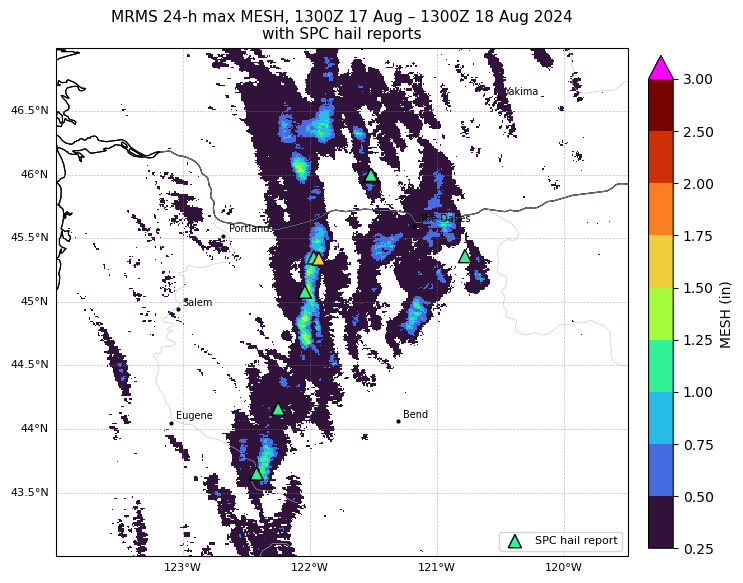

In [10]:
swath_keys = list_mesh_keys('MESH_Max_1440min_00.50', event_end, event_end)
swath = load_mesh(swath_keys[event_end])
print(f"Max MESH in domain: {float(swath.max()):.2f} in")

plot_mesh(swath,
          f"MRMS 24-h max MESH, {event_end - timedelta(hours=24):%H%MZ %d %b} – {event_end:%H%MZ %d %b %Y}\n"
          "with SPC hail reports",
          os.path.join(output_dir, 'mesh_swath_event.png'),
          reports=reports)
plt.show()

## Hourly MESH swaths (60-min max) + loop

Each frame is the 60-min running max ending at the valid time; reports from that same hour are overlaid.

In [11]:
hourly_start = datetime(2024, 8, 17, 18, 0)  # convection starts in the afternoon
hourly_keys = list_mesh_keys('MESH_Max_60min_00.50', hourly_start, event_end)
hourly_keys = {t: k for t, k in hourly_keys.items() if t.minute == 0}

frame_dir = os.path.join(output_dir, 'hourly')
os.makedirs(frame_dir, exist_ok=True)

frame_paths = []
for t, key in hourly_keys.items():
    da = load_mesh(key)
    hr_reports = reports[(reports['datetime'] > t - timedelta(hours=1)) & (reports['datetime'] <= t)]
    out_path = os.path.join(frame_dir, f"mesh_60min_{t:%Y%m%d_%H%M}.png")
    fig, ax = plot_mesh(da, f"MRMS 60-min max MESH ending {t:%H%M UTC %d %b %Y}", out_path, reports=hr_reports)
    plt.close(fig)
    frame_paths.append(out_path)
    print(out_path)

c:\Users\miles\miniconda3\envs\mcs2\Lib\site-packages\cfgrib\xarray_plugin.py:132: FutureWarning: In a future version of xarray decode_timedelta will default to False rather than None. To silence this warning, set decode_timedelta to True, False, or a 'CFTimedeltaCoder' instance.
  vars, attrs, coord_names = xr.conventions.decode_cf_variables(


./mesh_plots\hourly\mesh_60min_20240817_1800.png


c:\Users\miles\miniconda3\envs\mcs2\Lib\site-packages\cfgrib\xarray_plugin.py:132: FutureWarning: In a future version of xarray decode_timedelta will default to False rather than None. To silence this warning, set decode_timedelta to True, False, or a 'CFTimedeltaCoder' instance.
  vars, attrs, coord_names = xr.conventions.decode_cf_variables(


./mesh_plots\hourly\mesh_60min_20240817_1900.png


c:\Users\miles\miniconda3\envs\mcs2\Lib\site-packages\cfgrib\xarray_plugin.py:132: FutureWarning: In a future version of xarray decode_timedelta will default to False rather than None. To silence this warning, set decode_timedelta to True, False, or a 'CFTimedeltaCoder' instance.
  vars, attrs, coord_names = xr.conventions.decode_cf_variables(


...

./mesh_plots\hourly\mesh_60min_20240818_1100.png


c:\Users\miles\miniconda3\envs\mcs2\Lib\site-packages\cfgrib\xarray_plugin.py:132: FutureWarning: In a future version of xarray decode_timedelta will default to False rather than None. To silence this warning, set decode_timedelta to True, False, or a 'CFTimedeltaCoder' instance.
  vars, attrs, coord_names = xr.conventions.decode_cf_variables(


./mesh_plots\hourly\mesh_60min_20240818_1200.png


c:\Users\miles\miniconda3\envs\mcs2\Lib\site-packages\cfgrib\xarray_plugin.py:132: FutureWarning: In a future version of xarray decode_timedelta will default to False rather than None. To silence this warning, set decode_timedelta to True, False, or a 'CFTimedeltaCoder' instance.
  vars, attrs, coord_names = xr.conventions.decode_cf_variables(


./mesh_plots\hourly\mesh_60min_20240818_1300.png


In [12]:
frames = [imageio.imread(p) for p in frame_paths]
imageio.mimsave(os.path.join(output_dir, 'mesh_60min_loop.gif'), frames, duration=0.8, loop=0)

C:\Users\miles\AppData\Local\Temp\ipykernel_21912\1322335032.py:1: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  frames = [imageio.imread(p) for p in frame_paths]


## Instantaneous MESH at a chosen time

`MESH_00.50` is produced every ~2 min; useful for matching a radar scan or a specific report.

c:\Users\miles\miniconda3\envs\mcs2\Lib\site-packages\cfgrib\xarray_plugin.py:132: FutureWarning: In a future version of xarray decode_timedelta will default to False rather than None. To silence this warning, set decode_timedelta to True, False, or a 'CFTimedeltaCoder' instance.
  vars, attrs, coord_names = xr.conventions.decode_cf_variables(


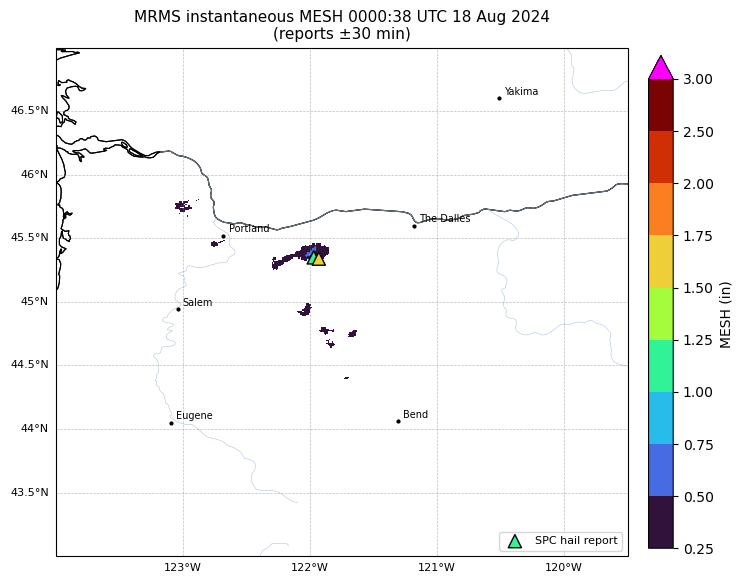

In [13]:
target = datetime(2024, 8, 18, 0, 0)  # e.g. near the Zigzag ping-pong-ball report
inst_keys = list_mesh_keys('MESH_00.50', target - timedelta(minutes=5), target + timedelta(minutes=5))
t, key = nearest_key(inst_keys, target)
da = load_mesh(key)
near = reports[(reports['datetime'] - t).abs() <= timedelta(minutes=30)]
plot_mesh(da, f"MRMS instantaneous MESH {t:%H%M:%S UTC %d %b %Y}\n(reports ±30 min)",
          os.path.join(output_dir, f"mesh_inst_{t:%Y%m%d_%H%M%S}.png"), reports=near)
plt.show()